# EcoSort AI: model training and evaluation (notebook 03)

Run notebooks 01 and 02 first. This notebook reads the group-aware splits saved by notebook 02 (`splits/`), then:

1. Builds a **MobileNetV2 transfer-learning** classifier (ImageNet weights).
2. Trains in two phases: (1) new classification head on a frozen base, (2) fine-tuning of the top layers at a low learning rate.
3. Evaluates once on the held-out test set with accuracy, loss, precision, recall, F1, a confusion matrix and per-class results.
4. Looks at confidence, so uncertain predictions can be flagged instead of trusted.
5. Saves the model (`.keras` plus an `.h5` copy), metrics and metadata for the API and dashboard.

**Use a GPU runtime** (Runtime > Change runtime type > T4 GPU). Training on CPU works but is slow.

Optimization techniques used (for the rubric and the report): pretrained model, data augmentation, dropout, L2 regularization, class weights, early stopping, learning-rate reduction on plateau, and two-stage fine-tuning.

Design decision: MobileNetV2's pixel scaling is **inside** the model, so the API can feed raw 0-255 pixels and training and serving cannot drift apart.

In [1]:
import os, sys, json, shutil, datetime
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

# ---- Configuration -------------------------------------------------------
SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
WEIGHTS = "imagenet"          # pretrained ImageNet weights (transfer learning)
DROPOUT = 0.3
L2 = 1e-4
EPOCHS_HEAD = 15              # phase 1: train the new head only (base frozen)
EPOCHS_FINE = 15              # phase 2: fine-tune the top of MobileNetV2
LR_HEAD = 1e-3
LR_FINE = 1e-5
FINE_TUNE_LAYERS = 30
CONFIDENCE_THRESHOLD = 0.70   # below this a prediction is flagged "uncertain"
MODEL_VERSION = "v1"

USE_DRIVE = True
COPY_TO_LOCAL = True          # copy images from Drive to Colab's local disk (much faster training)
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = Path("/content/drive/MyDrive/ecosort")
else:
    BASE_DIR = Path(".")

RAW_DIR = BASE_DIR / "data_raw"
SPLIT_DIR = BASE_DIR / "splits"
MODELS_DIR = BASE_DIR / "models"
REPORTS_DIR = BASE_DIR / "reports"
FIG_DIR = REPORTS_DIR / "figures"
for d in (MODELS_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

needed = ["train.csv", "val.csv", "test.csv", "class_names.json", "class_weights.json"]
missing = [f for f in needed if not (SPLIT_DIR / f).exists()]
if missing:
    raise FileNotFoundError(f"Missing {missing} in {SPLIT_DIR}. Run notebook 02 first.")

tf.keras.utils.set_random_seed(SEED)
gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow", tf.__version__, "| GPUs found:", len(gpus))
if not gpus:
    print("WARNING: no GPU. In Colab: Runtime > Change runtime type > T4 GPU.")

Mounted at /content/drive
TensorFlow 2.21.0 | GPUs found: 1


## 1. Locate the images (and copy them to fast local disk)
Reading thousands of small files from Google Drive every epoch is slow. Copying them once to the Colab VM's local disk makes training much faster. The copy is repeated only if the runtime was reset.

In [2]:
def find_class_root(base: Path) -> Path:
    for p in base.rglob("*"):
        if p.is_dir() and p.name == "RealWaste" and any(d.is_dir() for d in p.iterdir()):
            return p
    raise FileNotFoundError("Could not find a RealWaste folder with class subfolders. Run notebook 01.")

SOURCE_DATA_DIR = find_class_root(RAW_DIR)

if USE_DRIVE and COPY_TO_LOCAL:
    LOCAL_DATA_DIR = Path("/content/realwaste_local")
    if not LOCAL_DATA_DIR.exists():
        print("Copying images from Drive to local disk (a few minutes, once per runtime)...")
        tmp = Path(str(LOCAL_DATA_DIR) + "_tmp")
        if tmp.exists():
            shutil.rmtree(tmp)
        shutil.copytree(SOURCE_DATA_DIR, tmp)
        tmp.rename(LOCAL_DATA_DIR)
    DATA_DIR = LOCAL_DATA_DIR
else:
    DATA_DIR = SOURCE_DATA_DIR
print("Images read from:", DATA_DIR)

Copying images from Drive to local disk (a few minutes, once per runtime)...
Images read from: /content/realwaste_local


## 2. Load the saved splits
The split lists were created once in notebook 02, so train, validation and test are identical in every run. The test set is not used for training, early stopping or any tuning decision.

In [3]:
train_df = pd.read_csv(SPLIT_DIR / "train.csv")
val_df = pd.read_csv(SPLIT_DIR / "val.csv")
test_df = pd.read_csv(SPLIT_DIR / "test.csv")
class_names = json.load(open(SPLIT_DIR / "class_names.json"))
class_weights = {int(k): float(v) for k, v in json.load(open(SPLIT_DIR / "class_weights.json")).items()}
NUM_CLASSES = len(class_names)

all_paths = pd.concat([train_df, val_df, test_df])["path"]
absent = [p for p in all_paths if not (DATA_DIR / p).exists()]
assert not absent, f"{len(absent)} image files from the splits are missing, e.g. {absent[:3]}"

print("Classes:", class_names)
print("Train / val / test:", len(train_df), len(val_df), len(test_df))
print("Class weights:", {class_names[i]: round(w, 2) for i, w in class_weights.items()})

Classes: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
Train / val / test: 3325 716 711
Class weights: {'Cardboard': 1.15, 'Food Organics': 1.28, 'Glass': 1.25, 'Metal': 0.67, 'Miscellaneous Trash': 1.07, 'Paper': 1.06, 'Plastic': 0.57, 'Textile Trash': 1.63, 'Vegetation': 1.22}


## 3. Input pipeline
Same loading and augmentation as notebook 02, except that pixel scaling now happens inside the model. Augmentation is applied to the training set only.

In [4]:
AUTOTUNE = tf.data.AUTOTUNE

augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomBrightness(0.1, value_range=(0, 255)),
    tf.keras.layers.RandomContrast(0.1),
], name="augmentation")

def load_image(filepath):
    img = tf.io.read_file(filepath)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img.set_shape((IMG_SIZE, IMG_SIZE, 3))
    return img          # float32, pixel values 0-255

def make_dataset(frame, root, training=False, batch_size=BATCH_SIZE):
    # frame needs 'path' (relative to root) and 'label' columns
    paths = [str(Path(root) / p) for p in frame["path"]]
    labels = frame["label"].values.astype("int32")
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(lambda p, y: (load_image(p), y), num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(lambda x, y: (augmentation(x, training=True), y), num_parallel_calls=AUTOTUNE)
    return ds.batch(batch_size).prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, DATA_DIR, training=True)
val_ds = make_dataset(val_df, DATA_DIR)
test_ds = make_dataset(test_df, DATA_DIR)

## 4. Model: MobileNetV2 transfer learning
- **Pretrained base** (ImageNet) already knows edges, textures and shapes, so we need far less data and time than training a CNN from scratch.
- **Scaling layer** converts 0-255 pixels to the -1 to 1 range MobileNetV2 expects.
- **Head**: global average pooling, dropout, and a 9-way softmax with L2 weight regularization.
- The base starts **frozen**, so the randomly initialized head cannot damage the pretrained features.

In [5]:
def build_model():
    inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image")
    x = tf.keras.layers.Rescaling(1 / 127.5, offset=-1, name="mobilenet_scaling")(inputs)
    base = tf.keras.applications.MobileNetV2(
        input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights=WEIGHTS)
    base.trainable = False
    x = base(x, training=False)          # keep BatchNorm in inference mode
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(DROPOUT)(x)
    outputs = tf.keras.layers.Dense(
        NUM_CLASSES, activation="softmax",
        kernel_regularizer=tf.keras.regularizers.l2(L2), name="waste_class")(x)
    return tf.keras.Model(inputs, outputs, name="ecosort_mobilenetv2"), base

model, base_model = build_model()
model.compile(optimizer=tf.keras.optimizers.Adam(LR_HEAD),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "ecosort_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_scaling (Rescaling)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ waste_class (Dense)             │ (None, 9)              │        11,529 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,269,513 (8.66 MB)

 Trainable params: 11,529 (45.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 5. Phase 1: train the new head (base frozen)
Early stopping watches validation loss and restores the best weights. The learning rate is halved when validation loss stops improving. Class weights stop plastic and metal from dominating.

In [6]:
def make_callbacks(tag):
    return [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4,
                                         restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                             patience=2, min_lr=1e-7, verbose=1),
        tf.keras.callbacks.ModelCheckpoint(str(MODELS_DIR / f"checkpoint_{tag}.keras"),
                                           monitor="val_loss", save_best_only=True),
    ]

history_head = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD,
                         class_weight=class_weights, callbacks=make_callbacks("head"))

Epoch 1/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 116s 849ms/step - accuracy: 0.4665 - loss: 1.5007 - val_accuracy: 0.6704 - val_loss: 0.9412 - learning_rate: 0.0010
Epoch 2/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 52s 499ms/step - accuracy: 0.6571 - loss: 0.9212 - val_accuracy: 0.7151 - val_loss: 0.8104 - learning_rate: 0.0010
Epoch 3/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 54s 518ms/step - accuracy: 0.7023 - loss: 0.7847 - val_accuracy: 0.7318 - val_loss: 0.7368 - learning_rate: 0.0010
Epoch 4/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 52s 495ms/step - accuracy: 0.7260 - loss: 0.7099 - val_accuracy: 0.7598 - val_loss: 0.6926 - learning_rate: 0.0010
Epoch 5/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 53s 513ms/step - accuracy: 0.7522 - loss: 0.6622 - val_accuracy: 0.7486 - val_loss: 0.7154 - learning_rate: 0.0010
Epoch 6/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 478ms/step - accuracy: 0.7513 - loss: 0.6386
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
104/104 ━━━━━━━━━━━━━━━━━━━━ 81s 507ms/step - accuracy: 0.76

## 6. Phase 2: fine-tune the top of MobileNetV2
The last layers are unfrozen and trained with a very small learning rate, so they adapt to waste images without destroying what they learned from ImageNet. BatchNorm layers stay frozen, which is the standard safe practice.

In [7]:
base_model.trainable = True
for layer in base_model.layers[:-FINE_TUNE_LAYERS]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

trainable_params = int(sum(np.prod(w.shape) for w in model.trainable_weights))
print("Trainable parameters in phase 2:", trainable_params)

model.compile(optimizer=tf.keras.optimizers.Adam(LR_FINE),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])

epochs_done = len(history_head.history["loss"])
history_fine = model.fit(train_ds, validation_data=val_ds,
                         initial_epoch=epochs_done, epochs=epochs_done + EPOCHS_FINE,
                         class_weight=class_weights, callbacks=make_callbacks("fine"))

Trainable parameters in phase 2: 1522249
Epoch 16/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 80s 608ms/step - accuracy: 0.8021 - loss: 0.5081 - val_accuracy: 0.7919 - val_loss: 0.6097 - learning_rate: 1.0000e-05
Epoch 17/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 52s 496ms/step - accuracy: 0.8093 - loss: 0.4885 - val_accuracy: 0.7919 - val_loss: 0.6111 - learning_rate: 1.0000e-05
Epoch 18/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 53s 501ms/step - accuracy: 0.8250 - loss: 0.4669 - val_accuracy: 0.7947 - val_loss: 0.5814 - learning_rate: 1.0000e-05
Epoch 19/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 54s 517ms/step - accuracy: 0.8337 - loss: 0.4390 - val_accuracy: 0.8031 - val_loss: 0.5464 - learning_rate: 1.0000e-05
Epoch 20/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 79s 492ms/step - accuracy: 0.8382 - loss: 0.4144 - val_accuracy: 0.8031 - val_loss: 0.5551 - learning_rate: 1.0000e-05
Epoch 21/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 474ms/step - accuracy: 0.8339 - loss: 0.4095
Epoch 21: ReduceLROnPlateau reducing learning rate to 4.99999987368937

## 7. Training curves
Look for the gap between training and validation. A large and growing gap means overfitting. The dashed line marks the start of fine-tuning.

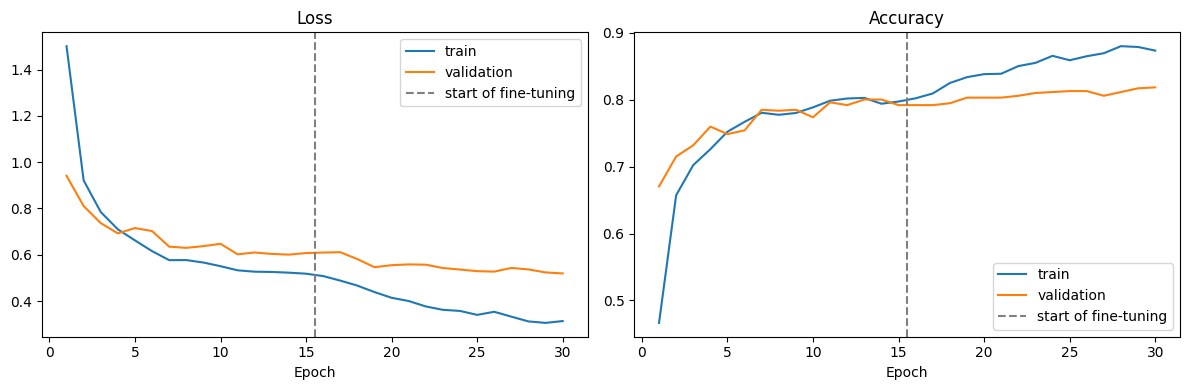

Best validation accuracy: 0.8184 (epoch 30)
Lowest validation loss:   0.5195 (epoch 30)


In [8]:
keys = ["loss", "accuracy", "val_loss", "val_accuracy"]
history = {k: list(history_head.history[k]) + list(history_fine.history[k]) for k in keys}
boundary = len(history_head.history["loss"])
epochs_axis = np.arange(1, len(history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, title in [(axes[0], "loss", "Loss"), (axes[1], "accuracy", "Accuracy")]:
    ax.plot(epochs_axis, history[metric], label="train")
    ax.plot(epochs_axis, history["val_" + metric], label="validation")
    ax.axvline(boundary + 0.5, color="gray", linestyle="--", label="start of fine-tuning")
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

print("Best validation accuracy: %.4f (epoch %d)" % (max(history["val_accuracy"]), int(np.argmax(history["val_accuracy"])) + 1))
print("Lowest validation loss:   %.4f (epoch %d)" % (min(history["val_loss"]), int(np.argmin(history["val_loss"])) + 1))

## 8. Save the model
The `.keras` file is the primary format. An `.h5` copy is also saved because the assignment lists `.h5`, `.tf` and `.pkl` as accepted formats.

In [9]:
MODEL_PATH = MODELS_DIR / f"ecosort_mobilenetv2_{MODEL_VERSION}.keras"
H5_PATH = MODELS_DIR / f"ecosort_mobilenetv2_{MODEL_VERSION}.h5"

model.save(MODEL_PATH)
print("Saved:", MODEL_PATH, "(%.1f MB)" % (MODEL_PATH.stat().st_size / 1e6))
try:
    model.save(H5_PATH)
    print("Saved:", H5_PATH, "(%.1f MB)" % (H5_PATH.stat().st_size / 1e6))
except Exception as e:
    print("Could not save the .h5 copy (the .keras file is still valid):", e)

Saved: /content/drive/MyDrive/ecosort/models/ecosort_mobilenetv2_v1.keras (21.9 MB)
Saved: /content/drive/MyDrive/ecosort/models/ecosort_mobilenetv2_v1.h5 (21.6 MB)


## 9. Evaluation on the held-out test set
Metrics reported: **accuracy, loss, precision, recall and F1** (macro and weighted), plus per-class results and a confusion matrix.
- *Macro* averages the classes equally, so a weak small class is not hidden.
- *Weighted* averages by class size.
The validation numbers are shown too, so you can compare. The test set is evaluated here for the first time.

In [10]:
def predict_split(frame, root):
    ds = make_dataset(frame, root)           # not shuffled, so order matches the frame
    probs = model.predict(ds, verbose=0)
    return frame["label"].values, probs.argmax(axis=1), probs

def summarize(name, y_true, y_pred, probs):
    labels = np.unique(np.concatenate([y_true, y_pred]))
    loss = float(tf.keras.losses.sparse_categorical_crossentropy(y_true, probs).numpy().mean())
    p_m, r_m, f_m, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels, average="macro", zero_division=0)
    p_w, r_w, f_w, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels, average="weighted", zero_division=0)
    result = {
        "n_images": int(len(y_true)), "loss": loss,
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision_macro": float(p_m), "recall_macro": float(r_m), "f1_macro": float(f_m),
        "precision_weighted": float(p_w), "recall_weighted": float(r_w), "f1_weighted": float(f_w),
    }
    print(f"=== {name} ({result['n_images']} images) ===")
    for k in ["loss", "accuracy", "precision_macro", "recall_macro", "f1_macro",
              "precision_weighted", "recall_weighted", "f1_weighted"]:
        print(f"{k:<20} {result[k]:.4f}")
    return result

yv, pv, probs_v = predict_split(val_df, DATA_DIR)
val_metrics = summarize("VALIDATION", yv, pv, probs_v)
print()
yt, pt, probs_t = predict_split(test_df, DATA_DIR)
test_metrics = summarize("TEST", yt, pt, probs_t)

=== VALIDATION (716 images) ===
loss                 0.5162
accuracy             0.8184
precision_macro      0.8212
recall_macro         0.8310
f1_macro             0.8216
precision_weighted   0.8240
recall_weighted      0.8184
f1_weighted          0.8171

=== TEST (711 images) ===
loss                 0.5152
accuracy             0.8186
precision_macro      0.8242
recall_macro         0.8257
f1_macro             0.8225
precision_weighted   0.8228
recall_weighted      0.8186
f1_weighted          0.8184


In [11]:
report_text = classification_report(yt, pt, labels=list(range(NUM_CLASSES)),
                                    target_names=class_names, digits=3, zero_division=0)
print(report_text)
report_dict = classification_report(yt, pt, labels=list(range(NUM_CLASSES)),
                                    target_names=class_names, output_dict=True, zero_division=0)

                     precision    recall  f1-score   support

          Cardboard      0.853     0.817     0.835        71
      Food Organics      0.929     0.852     0.889        61
              Glass      0.697     0.855     0.768        62
              Metal      0.916     0.831     0.871       118
Miscellaneous Trash      0.750     0.640     0.691        75
              Paper      0.784     0.920     0.847        75
            Plastic      0.761     0.766     0.764       137
      Textile Trash      0.844     0.826     0.835        46
         Vegetation      0.884     0.924     0.904        66

           accuracy                          0.819       711
          macro avg      0.824     0.826     0.822       711
       weighted avg      0.823     0.819     0.818       711



## 10. Confusion matrix
The raw matrix shows counts. The normalized one shows the share of each true class, so small classes are readable. Off-diagonal cells are the mistakes: read each row as "images of this class were predicted as...".

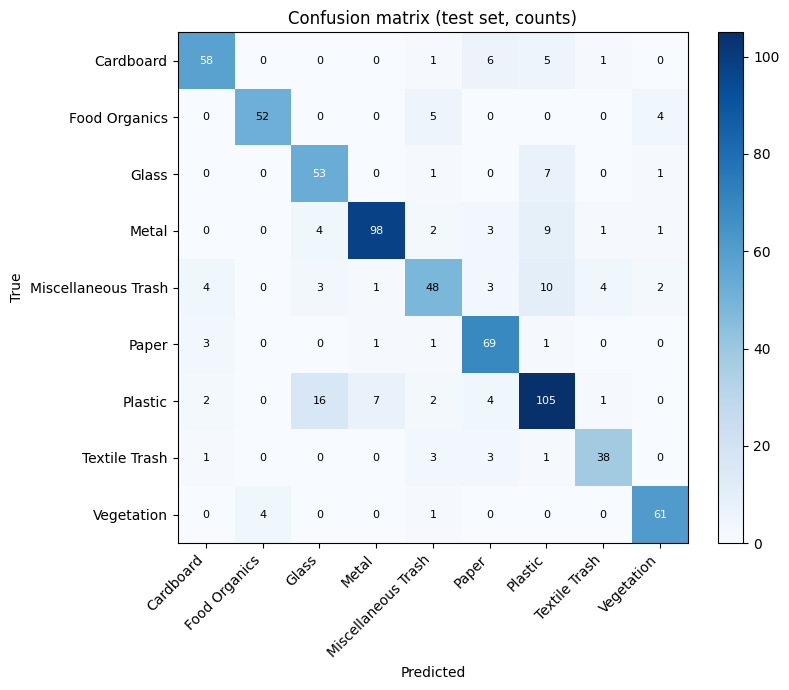

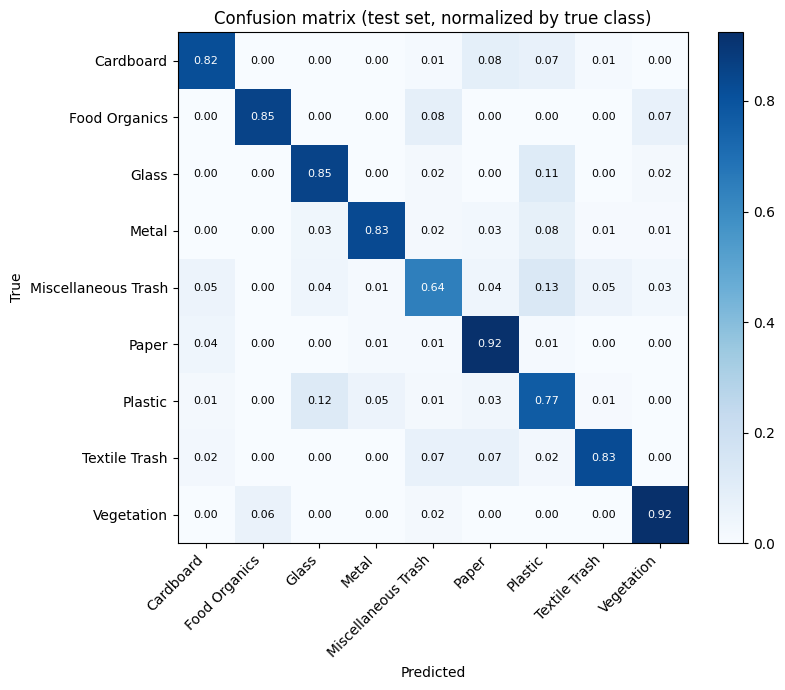

In [12]:
def plot_confusion(cm, labels, title, normalize=False, path=None):
    data = cm.astype(float) / cm.sum(axis=1, keepdims=True).clip(min=1) if normalize else cm
    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(data, cmap="Blues")
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45, ha="right")
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title)
    thresh = data.max() / 2
    for i in range(len(labels)):
        for j in range(len(labels)):
            text = f"{data[i, j]:.2f}" if normalize else str(int(data[i, j]))
            ax.text(j, i, text, ha="center", va="center", fontsize=8,
                    color="white" if data[i, j] > thresh else "black")
    fig.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout()
    if path:
        plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()

cm = confusion_matrix(yt, pt, labels=list(range(NUM_CLASSES)))
plot_confusion(cm, class_names, "Confusion matrix (test set, counts)", path=FIG_DIR / "confusion_matrix.png")
plot_confusion(cm, class_names, "Confusion matrix (test set, normalized by true class)",
               normalize=True, path=FIG_DIR / "confusion_matrix_normalized.png")

In [13]:
pairs = [(class_names[i], class_names[j], int(cm[i, j]))
         for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j and cm[i, j] > 0]
pairs.sort(key=lambda t: -t[2])
print("Most frequent confusions (true -> predicted):")
for true_c, pred_c, n in pairs[:6]:
    print(f"  {true_c:<22} -> {pred_c:<22} {n} images")

per_class = pd.DataFrame({k: v for k, v in report_dict.items() if k in class_names}).T
print("\nWeakest classes by F1:")
print(per_class.sort_values("f1-score")[["precision", "recall", "f1-score", "support"]].head(3).round(3))

Most frequent confusions (true -> predicted):
  Plastic                -> Glass                  16 images
  Miscellaneous Trash    -> Plastic                10 images
  Metal                  -> Plastic                9 images
  Glass                  -> Plastic                7 images
  Plastic                -> Metal                  7 images
  Cardboard              -> Paper                  6 images

Weakest classes by F1:
                     precision  recall  f1-score  support
Miscellaneous Trash      0.750   0.640     0.691     75.0
Plastic                  0.761   0.766     0.764    137.0
Glass                    0.697   0.855     0.768     62.0


## 11. Confidence: when should the system say "I'm not sure"?
For a waste-sorting bin, a confident wrong answer is worse than asking the user to try again. The table shows what happens if predictions below a confidence threshold are flagged as uncertain: **coverage** is the share of images still answered, and **accuracy** is measured on those only.

In [14]:
conf_t = probs_t.max(axis=1)
correct = (pt == yt)
print("Mean confidence when correct:   %.3f" % conf_t[correct].mean())
if (~correct).any():
    print("Mean confidence when incorrect: %.3f" % conf_t[~correct].mean())

rows = []
for t in [0.0, 0.5, 0.6, 0.7, 0.8, 0.9]:
    keep = conf_t >= t
    rows.append({"threshold": t, "coverage": keep.mean(),
                 "accuracy_on_answered": correct[keep].mean() if keep.any() else np.nan,
                 "flagged_uncertain": int((~keep).sum())})
coverage_table = pd.DataFrame(rows)
print()
print(coverage_table.round(3).to_string(index=False))
print(f"\nCurrent CONFIDENCE_THRESHOLD = {CONFIDENCE_THRESHOLD}. Pick the value that gives acceptable accuracy while still answering most images.")

Mean confidence when correct:   0.877
Mean confidence when incorrect: 0.648

 threshold  coverage  accuracy_on_answered  flagged_uncertain
       0.0     1.000                 0.819                  0
       0.5     0.914                 0.849                 61
       0.6     0.844                 0.882                111
       0.7     0.775                 0.895                160
       0.8     0.658                 0.936                243
       0.9     0.536                 0.963                330

Current CONFIDENCE_THRESHOLD = 0.7. Pick the value that gives acceptable accuracy while still answering most images.


## 12. Look at the mistakes
The most confident wrong predictions are the most informative: they show whether the model is wrong because the image is genuinely ambiguous (e.g. a metal-coated wrapper) or because of a real weakness.

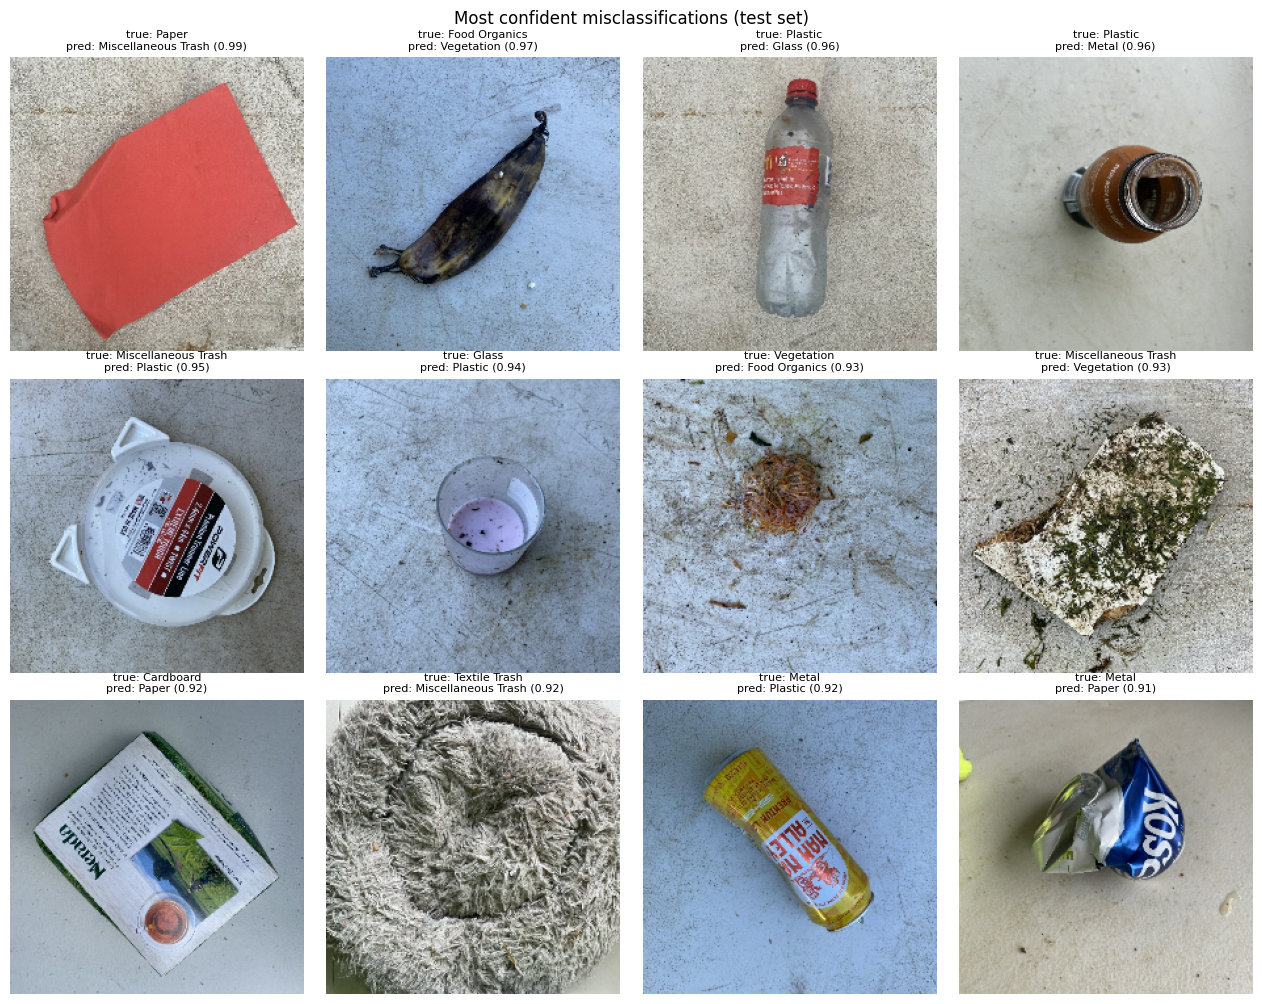

129 of 711 test images misclassified


In [15]:
wrong = np.where(pt != yt)[0]
if len(wrong) == 0:
    print("No misclassified test images.")
else:
    order = wrong[np.argsort(-conf_t[wrong])][:12]
    cols = 4
    rows_n = int(np.ceil(len(order) / cols))
    plt.figure(figsize=(3.2 * cols, 3.4 * rows_n))
    for k, idx in enumerate(order):
        img = load_image(str(DATA_DIR / test_df.iloc[idx]["path"]))
        plt.subplot(rows_n, cols, k + 1)
        plt.imshow(np.clip(img.numpy(), 0, 255).astype("uint8")); plt.axis("off")
        plt.title(f"true: {class_names[yt[idx]]}\npred: {class_names[pt[idx]]} ({conf_t[idx]:.2f})", fontsize=8)
    plt.suptitle("Most confident misclassifications (test set)")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "misclassified_examples.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(len(wrong), "of", len(yt), "test images misclassified")

## 13. Local Kigali test set (separate)
If you added photos in `local_test/<ClassName>/` and ran the last cell of notebook 02, the model is evaluated on them here. They were never used for training, early stopping or tuning. Expect lower scores than on the RealWaste test set. That gap is a finding for the report, not a failure.

In [16]:
local_metrics = None
local_csv = SPLIT_DIR / "local_test.csv"
LOCAL_DIR = BASE_DIR / "local_test"

if local_csv.exists() and LOCAL_DIR.exists():
    local_df = pd.read_csv(local_csv)
    yl, pl, probs_l = predict_split(local_df, LOCAL_DIR)
    local_metrics = summarize("LOCAL KIGALI TEST", yl, pl, probs_l)
    present = np.unique(np.concatenate([yl, pl]))
    print()
    print(classification_report(yl, pl, labels=present, target_names=[class_names[i] for i in present],
                                digits=3, zero_division=0))
    print("Note: with few photos per class, per-class numbers are indicative only.")
else:
    print("No local test set yet. Local evaluation is pending; state this in the report.")

No local test set yet. Local evaluation is pending; state this in the report.


## 14. Prediction function and save/load check
`predict_image` is the logic the API will wrap. It returns the class, the confidence, the top 3 candidates and an `uncertain` flag. Mapping a class to a disposal stream is a separate layer, built later. The model itself only recognizes the waste category.

In [17]:
def predict_image(image_path, net=None, top_k=3, threshold=CONFIDENCE_THRESHOLD):
    net = net or model
    img = load_image(str(image_path))
    probs = net.predict(tf.expand_dims(img, 0), verbose=0)[0]
    order = probs.argsort()[::-1][:top_k]
    top = [{"class": class_names[i], "confidence": round(float(probs[i]), 4)} for i in order]
    return {"predicted_class": top[0]["class"], "confidence": top[0]["confidence"],
            "uncertain": top[0]["confidence"] < threshold, "top_k": top}

# Reload the saved file and confirm it behaves identically to the in-memory model
reloaded = tf.keras.models.load_model(MODEL_PATH)
sample_paths = test_df.sample(3, random_state=SEED)
batch = tf.stack([load_image(str(DATA_DIR / p)) for p in sample_paths["path"]])
same = np.allclose(model.predict(batch, verbose=0), reloaded.predict(batch, verbose=0), atol=1e-5)
print("Reloaded model matches the trained model:", same)
assert same

for _, row in sample_paths.iterrows():
    out = predict_image(DATA_DIR / row["path"], net=reloaded)
    print(f"true={row['class']:<20} -> {out['predicted_class']:<20} conf={out['confidence']:.2f} uncertain={out['uncertain']}")

Reloaded model matches the trained model: True
true=Plastic              -> Paper                conf=0.45 uncertain=True
true=Paper                -> Paper                conf=0.72 uncertain=False
true=Metal                -> Metal                conf=0.40 uncertain=True


## 15. Save metrics and metadata
`metrics.json` feeds the dashboard and the report. `model_metadata.json` is what the API reads to report model version, classes and the confidence threshold. When retraining is added, a new model is promoted only if it beats the current one on this same fixed test set.

In [18]:
def to_jsonable(o):
    if hasattr(o, "tolist"):
        return o.tolist()
    if hasattr(o, "item"):
        return o.item()
    return str(o)

created = datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds")

metrics_out = {
    "model_version": MODEL_VERSION, "created_utc": created,
    "validation": val_metrics, "test": test_metrics, "local_test": local_metrics,
    "per_class_test": report_dict,
    "confusion_matrix_test": cm.tolist(), "class_names": class_names,
    "confidence_coverage_test": coverage_table.to_dict(orient="records"),
    "history": history, "phase1_epochs": boundary,
}
with open(REPORTS_DIR / "metrics.json", "w") as f:
    json.dump(metrics_out, f, indent=2, default=to_jsonable)

metadata = {
    "model_version": MODEL_VERSION, "created_utc": created,
    "model_file": MODEL_PATH.name, "h5_file": H5_PATH.name,
    "architecture": "MobileNetV2 (ImageNet) + GAP + Dropout + Dense softmax",
    "input_size": [IMG_SIZE, IMG_SIZE, 3], "input_range": "raw 0-255 pixels (scaling is inside the model)",
    "class_names": class_names, "confidence_threshold": CONFIDENCE_THRESHOLD,
    "test_accuracy": test_metrics["accuracy"], "test_f1_macro": test_metrics["f1_macro"],
    "train_size": int(len(train_df)), "val_size": int(len(val_df)), "test_size": int(len(test_df)),
    "seed": SEED, "tensorflow_version": tf.__version__,
}
with open(MODELS_DIR / "model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2, default=to_jsonable)

print("Saved:", REPORTS_DIR / "metrics.json")
print("Saved:", MODELS_DIR / "model_metadata.json")
print("Figures in:", FIG_DIR)

Saved: /content/drive/MyDrive/ecosort/reports/metrics.json
Saved: /content/drive/MyDrive/ecosort/models/model_metadata.json
Figures in: /content/drive/MyDrive/ecosort/reports/figures


## 16. Notes for the report (fill in after running)
- Final test accuracy, macro F1, macro precision, macro recall, and test loss:
- Validation vs test scores (a big gap would suggest the validation set was overfitted through tuning):
- Overfitting check from the training curves: size of the train/validation gap, and which epoch was best:
- Weakest classes and the most frequent confusions, with a likely physical reason (e.g. glass vs plastic, paper vs cardboard):
- What the confidence table shows, and the threshold chosen for the app:
- Local Kigali test result and how it compares with the RealWaste test set (or "pending"):
- Optimization techniques used and why each helps: pretrained base, augmentation, dropout, L2, class weights, early stopping, LR reduction, fine-tuning:
- Limitations: Australian landfill photos, sorted per-item single-label images, near-duplicates handled with a perceptual-hash threshold only:

**Next (notebook/module 04):** move the reusable code into `src/preprocessing.py`, `src/model.py`, `src/prediction.py`, then build the FastAPI service (health, predict, upload, retrain, status).